# Chương 2. Học máy cơ bản: dự đoán khoản vay có trả được nợ hay không

**Vấn đề.** Một nền tảng cho vay nhận hồ sơ xin vay và phải trả lời: người này nhiều khả năng sẽ trả đủ hay sẽ bỏ cuộc
giữa chừng (khoản vay bị *xóa nợ*, tiếng Anh *charged off*)? Đây là bài toán **phân loại nhị phân trên dữ liệu bảng**:
mỗi dòng là một khoản vay, mỗi cột là một thông tin trong hồ sơ, nhãn `default` = 1 nếu khoản vay không được trả đủ.

**Dữ liệu.** Lending Club (cho vay ngang hàng ở Mỹ), bản sao Hugging Face `codesignal/lending-club-loan-accepted`, giấy phép CC0.
Từ 2.260.701 khoản vay gốc, giữ khoản vay **36 tháng phát hành 01/2012 đến 06/2015** có kết cục cuối cùng (427.252 khoản) rồi
**lấy mẫu ngẫu nhiên 150.000 dòng** lưu CSV. Khoản còn "đang trả" bị loại để nhãn không bị lệch. Mọi cột đưa vào mô hình đều biết
*tại thời điểm xin vay* (không dùng số tiền đã trả hay ngày thanh toán, vì đó là rò rỉ tương lai).

**Ba mô hình so sánh.** Hồi quy logistic (một công thức cộng điểm), rừng ngẫu nhiên (nhiều cây quyết định bỏ phiếu) và mạng MLP
d → 16 → 1 viết bằng ba cách (NumPy tự viết, PyTorch, Keras) với cùng trọng số khởi tạo.

**Cách chạy.** *Restart Kernel → Run All*, khoảng 3–5 phút trên CPU. Huấn luyện dùng đúng cấu hình của kết quả đã lưu
(mini-batch 256, tối đa 25 epoch, dừng sớm sau 5 epoch không cải thiện, hạt giống 11) nên số đo gần như trùng bản đã lưu.
Notebook không ghi đè dữ liệu hay kết quả.

In [1]:
# Cell ML-01
import os, sys, json, time, inspect
from pathlib import Path
for name in ('OMP_NUM_THREADS', 'OPENBLAS_NUM_THREADS', 'MKL_NUM_THREADS'):
    os.environ[name] = '4'
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
os.environ['KERAS_BACKEND'] = 'tensorflow'
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src/tieuluan/loan.py').exists())
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (balanced_accuracy_score, confusion_matrix, precision_score, recall_score,
                             roc_auc_score, roc_curve)
from src.tieuluan import loan
from src.tieuluan.experiment_models import build_models, fit_model, predict_logits

RESULTS = ROOT / 'results/tieuluan/full'
records = [json.loads(p.read_text(encoding='utf-8')) for p in sorted(RESULTS.glob('loan_default__*.json'))]
sigmoid = lambda z: .5 * (1 + np.tanh(np.asarray(z, dtype=float) / 2))
print('Dự án:', ROOT, '| số bản ghi huấn luyện đã lưu của Chương 2:', len(records))

Dự án: E:\WINDOW\Project\intelligent-system-assignment-01 | số bản ghi huấn luyện đã lưu của Chương 2: 16


## 1. Nhìn dữ liệu thô

Ô dưới đọc tệp CSV gốc (không phải ma trận đã xử lý), in vài dòng, kích thước, tỉ lệ nhãn và cột thiếu giá trị.
**Cách đọc:** `default` = 1 là khoản vay không được trả đủ. Tỉ lệ này chỉ khoảng 14%, tức dữ liệu **mất cân bằng**:
một mô hình ngây ngô luôn đoán "trả đủ" đã đúng khoảng 86%. Vì vậy báo cáo dùng ROC-AUC, recall, balanced accuracy thay vì
chỉ accuracy.

In [2]:
# Cell ML-02
raw = pd.read_csv(ROOT / 'data/tieuluan/raw/lending_club/loans_36m_2012_2015_150k.csv', parse_dates=['issue_d'])
display(raw.head())
print('Kích thước:', raw.shape, '| tỉ lệ không trả đủ:', round(raw.default.mean(), 4),
      '| luôn đoán "trả đủ" đúng:', round(1 - raw.default.mean(), 4))
miss = raw.isna().mean()
display(miss[miss > 0].rename('tỉ lệ thiếu').to_frame())

,issue_d,loan_status,grade,sub_grade,loan_amnt,int_rate,annual_inc,dti,fico,emp_length,...,total_acc,pub_rec,pub_rec_bankruptcies,revol_bal,revol_util,credit_history_years,home_ownership,verification_status,purpose,default
0,2012-01-01,Fully Paid,C,C3,11000.0,14.65,51600.0,14.93,677.0,8.0,...,20.0,0.0,0.0,13047.0,71.0,8.999316,MORTGAGE,Not Verified,debt_consolidation,0
1,2012-01-01,Charged Off,B,B4,9200.0,12.42,35000.0,24.45,687.0,8.0,...,28.0,0.0,0.0,9035.0,53.1,11.835729,RENT,Not Verified,debt_consolidation,1
2,2012-01-01,Fully Paid,D,D4,13250.0,17.58,75000.0,0.80,667.0,3.0,...,9.0,0.0,0.0,1321.0,3.9,12.999316,MORTGAGE,Verified,debt_consolidation,0
3,2012-01-01,Fully Paid,E,E1,22750.0,18.64,55000.0,16.66,667.0,4.0,...,33.0,0.0,0.0,30571.0,75.9,8.670773,RENT,Verified,credit_card,0
4,2012-01-01,Charged Off,B,B3,14000.0,11.71,70000.0,16.66,692.0,7.0,...,25.0,0.0,0.0,21488.0,77.0,10.083504,MORTGAGE,Source Verified,debt_consolidation,1


Kích thước: (150000, 23) | tỉ lệ không trả đủ: 0.1376 | luôn đoán "trả đủ" đúng: 0.8624


,tỉ lệ thiếu
emp_length,0.055113
revol_util,0.000547


## 2. Chia tập theo thời gian, không chia ngẫu nhiên

Ngoài đời mô hình học từ quá khứ rồi chấm hồ sơ mới. Nếu trộn ngẫu nhiên, mô hình có thể gặp khoản vay cùng tháng với khoản đang
kiểm tra (rò rỉ thời gian). Vì vậy: **train** đến 31/08/2014, **validation** 09–12/2014 (dùng để chọn ngưỡng quyết định,
dừng sớm), **test** 01–06/2015 (chỉ đọc ở cuối). Biểu đồ cho thấy tỉ lệ không trả đủ **tăng dần theo thời gian**
(khoảng 12% năm 2013, 15% năm 2015): đây là *dịch chuyển phân phối*, một lý do mô hình ngoài đời luôn yếu hơn trên dữ liệu thử.

,so_mau,khong_tra_du,ti_le,tu,den
tap,,,,,
train,87535,11313,0.1292,2012-01-01,2014-08-01
val,20384,2916,0.1431,2014-09-01,2014-12-01
test,42081,6409,0.1523,2015-01-01,2015-06-01


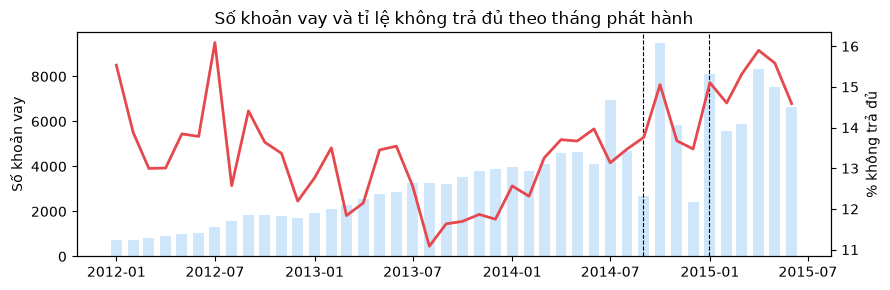

In [3]:
# Cell ML-03
TRAIN_END, VAL_END = pd.Timestamp('2014-08-31'), pd.Timestamp('2014-12-31')
part = np.where(raw.issue_d <= TRAIN_END, 'train', np.where(raw.issue_d <= VAL_END, 'val', 'test'))
summary = (raw.assign(tap=part).groupby('tap').agg(so_mau=('default', 'size'), khong_tra_du=('default', 'sum'),
           ti_le=('default', 'mean'), tu=('issue_d', 'min'), den=('issue_d', 'max')).loc[['train', 'val', 'test']])
display(summary.assign(ti_le=summary.ti_le.round(4)))
monthly = raw.groupby('issue_d').default.agg(['mean', 'size'])
fig, ax = plt.subplots(figsize=(9, 3))
ax.bar(monthly.index, monthly['size'], width=20, color='#cfe6fb', label='số khoản vay (trục trái)')
ax2 = ax.twinx()
ax2.plot(monthly.index, 100 * monthly['mean'], color='#e5484d', lw=2, label='% không trả đủ (trục phải)')
for edge in (TRAIN_END, VAL_END):
    ax.axvline(edge, color='k', ls='--', lw=.8)
ax.set_title('Số khoản vay và tỉ lệ không trả đủ theo tháng phát hành'); ax.set_ylabel('Số khoản vay'); ax2.set_ylabel('% không trả đủ')
plt.tight_layout(); plt.show()

## 3. Từ hồ sơ thô đến ma trận đặc trưng

`build_features` nhận bảng thô (các cột thông tin hồ sơ) và trả ma trận số. Các bước: (1) ép kiểu số; (2) tính **tiền góp hằng tháng**
bằng công thức niên kim `A·r / (1 − (1+r)^−n)` với A là số vay, r = lãi suất tháng, n = 36; (3) tính **gánh nặng trả nợ**
`payment_to_income` = tiền góp cả năm / thu nhập năm; (4) lấy log thu nhập và dư nợ để giảm lệch phải; (5) mã hóa one-hot cho
nhà ở, xác minh thu nhập, mục đích vay. Đầu ra 35 cột. **Cùng hàm này được dùng ở demo web**, nên người nhập tay và dữ liệu
huấn luyện đi qua đúng một pipeline.

In [4]:
# Cell ML-04
print(inspect.getsource(loan.monthly_payment))
features = loan.build_features(raw)
print('Ma trận đặc trưng:', features.shape)
display(features.head(3).T.round(3))
print('Ví dụ: vay 12.000 USD, lãi 13%/năm, 36 tháng => góp', round(float(loan.monthly_payment(12000, 13.0)), 2), 'USD/tháng')

def monthly_payment(amount, annual_rate_pct, months=TERM_MONTHS):
    """Tiền góp hằng tháng theo công thức niên kim: A·r / (1 − (1+r)^−n)."""
    r = np.asarray(annual_rate_pct, dtype=float) / 1200.0
    amount = np.asarray(amount, dtype=float)
    safe = np.where(r > 0, r, 1.0)
    return np.where(r > 0, amount * safe / (1 - (1 + safe) ** -months), amount / months)

Ma trận đặc trưng: (150000, 35)


,0,1,2
loan_amnt,11000.000,9200.000,13250.000
int_rate,14.650,12.420,17.580
annual_inc,51600.000,35000.000,75000.000
dti,14.930,24.450,0.800
fico,677.000,687.000,667.000
emp_length,8.000,8.000,3.000
delinq_2yrs,0.000,0.000,1.000
inq_last_6mths,1.000,0.000,1.000
open_acc,14.000,8.000,7.000
total_acc,20.000,28.000,9.000


Ví dụ: vay 12.000 USD, lãi 13%/năm, 36 tháng => góp 404.33 USD/tháng


## 4. Điền khuyết và chuẩn hóa chỉ học trên train

Giá trị thiếu (số năm đi làm, một ít mức dùng thẻ) được điền bằng **trung vị của train**; rồi mỗi cột được chuẩn hóa
`z = (x − mean_train) / std_train`. Nếu tính trung bình trên cả test, thông tin của test đã lọt vào đầu vào (*data leakage*).
Ô dưới tự tính lại các tham số từ train và **kiểm tra trùng khít** với tệp `processed/loan_default.npz` đã dùng để huấn luyện.

In [5]:
# Cell ML-05
is_train = (raw.issue_d <= TRAIN_END).to_numpy()
median = features[is_train].median()
filled = features.fillna(median)
mean, std = filled[is_train].mean(), filled[is_train].std(ddof=0).replace(0, 1.0)
with np.load(ROOT / 'data/tieuluan/processed/loan_default.npz', allow_pickle=False) as archive:
    data = {k: archive[k] for k in archive.files}
assert np.allclose(median.to_numpy(), data['imputer_median']) and np.allclose(mean.to_numpy(), data['scaler_mean'])
assert np.allclose(std.to_numpy(), data['scaler_scale'])
x, y, xv, yv, xt, yt = (data[k] for k in ['train_tabular', 'train_y', 'val_tabular', 'val_y', 'test_tabular', 'test_y'])
assert abs(x.mean()) < 1e-3 and len(y) == int(is_train.sum())
print('Khớp dữ liệu đã xử lý. train', x.shape, '| val', xv.shape, '| test', xt.shape)
print('Trung bình cột train sau chuẩn hóa ~ 0:', float(np.abs(x.mean(0)).max()), '; trên test lệch nhẹ (bình thường):',
      round(float(np.abs(xt.mean(0)).max()), 3))

Khớp dữ liệu đã xử lý. train (87535, 35) | val (20384, 35) | test (42081, 35)
Trung bình cột train sau chuẩn hóa ~ 0: 8.429832087131217e-05 ; trên test lệch nhẹ (bình thường): 0.369


## 5. Hai mô hình đối chứng: hồi quy logistic và rừng ngẫu nhiên

**Hồi quy logistic:** xác suất `p = σ(w·x + b)`, với σ(z) = 1/(1+e⁻ᶻ); học w, b bằng cực tiểu hóa cross-entropy. Mỗi trọng số cho biết
đặc trưng đó đẩy rủi ro lên hay xuống nên rất dễ giải thích. **Rừng ngẫu nhiên:** 150 cây quyết định (độ sâu tối đa 8, mỗi lá ≥ 20 mẫu)
mỗi cây học trên một mẫu bootstrap rồi lấy trung bình xác suất. Cả hai là mô hình đơn giản nhưng thường rất mạnh trên dữ liệu bảng.

In [6]:
# Cell ML-06
def fit_sklearn(model, name):
    """Huấn luyện trên train, trả về xác suất val/test và thời gian."""
    start = time.perf_counter()
    model.fit(x, y)
    return {'name': name, 'val': model.predict_proba(xv)[:, 1], 'test': model.predict_proba(xt)[:, 1],
            'seconds': time.perf_counter() - start, 'model': model}

runs = {'Hồi quy logistic': fit_sklearn(LogisticRegression(max_iter=2000, C=1., random_state=11), 'logistic'),
        'Rừng ngẫu nhiên': fit_sklearn(RandomForestClassifier(n_estimators=150, max_depth=8, min_samples_leaf=20, n_jobs=4,
                                                              random_state=11), 'random_forest')}
for name, r in runs.items():
    print(f"{name}: ROC-AUC test = {roc_auc_score(yt, r['test']):.4f} ({r['seconds']:.1f} giây)")
weights = pd.Series(runs['Hồi quy logistic']['model'].coef_[0], index=data['feature_names']).sort_values()
display(pd.concat([weights.head(5), weights.tail(5)]).rename('trọng số (đã chuẩn hóa)').round(3).to_frame())

Hồi quy logistic: ROC-AUC test = 0.6780 (0.5 giây)
Rừng ngẫu nhiên: ROC-AUC test = 0.6773 (13.5 giây)


,trọng số (đã chuẩn hóa)
loan_amnt,-0.856
fico,-0.185
log_annual_inc,-0.119
log_revol_bal,-0.105
total_acc,-0.074
dti,0.104
open_acc,0.108
payment_to_income,0.188
int_rate,0.225
installment,0.808


**Đọc bảng trọng số.** Trọng số dương nghĩa là đặc trưng đó làm tăng khả năng không trả đủ (lãi suất, gánh nặng trả nợ, mức nợ trên thu nhập),
âm nghĩa là giảm (điểm FICO cao, thu nhập cao). Vì đã chuẩn hóa nên có thể so độ mạnh giữa các trọng số. **Lưu ý:** `loan_amnt` (số vay) và
`installment` (tiền góp hằng tháng) gần như cùng một đại lượng nên hai trọng số lớn, trái dấu, triệt tiêu nhau; đừng đọc riêng từng cái
(hiện tượng *đa cộng tuyến*): điều đáng tin hơn là tác động chung của chúng.

## 6. Mạng MLP: ba cách cài đặt, cùng một kiến trúc

MLP: `x (35 giá trị) → Dense(16) → ReLU → Dense(1) → logit`, rồi `p = σ(logit)`. Hàm mất mát là **BCE trên logit**
`max(z,0) − z·y + log(1+e^−|z|)` (ổn định số). Cả ba bản (NumPy tự viết có `forward/backward` riêng, PyTorch autograd, Keras)
dùng **cùng trọng số khởi tạo**, cùng thứ tự mini-batch 256, Adam (lr 0,001), cắt chuẩn gradient 1,0, dừng sớm theo BCE validation
và khôi phục checkpoint tốt nhất. `fit_model` làm tất cả; ta chỉ gọi và đo.

In [7]:
# Cell ML-07
print(inspect.getsource(loan.preprocess))
mlp = {}
rows = []
for framework, label in (('scratch', 'NumPy tự viết'), ('pytorch', 'PyTorch'), ('keras', 'Keras')):
    model = build_models('mlp', x.shape[1:], seed=11, frameworks=(framework,))[framework]
    fit = fit_model(model, framework, 'mlp', x, y, xv, yv, seed=11, epochs=25, batch_size=256, patience=5)
    mlp[framework] = {'val': sigmoid(predict_logits(model, framework, xv)), 'test': sigmoid(predict_logits(model, framework, xt))}
    saved = next(r for r in records if r['kind'] == 'mlp' and r['framework'] == framework and r['seed'] == 11)
    rows.append({'Cài đặt': label, 'Số epoch đã chạy': fit['epochs_run'], 'Epoch tốt nhất': fit['best_epoch'],
                 'Giây': round(fit['training_seconds'], 1), 'ROC-AUC test': round(roc_auc_score(yt, mlp[framework]['test']), 4),
                 'ROC-AUC đã lưu': round(saved['metrics']['roc_auc'], 4)})
display(pd.DataFrame(rows))

def preprocess(features, params):
    """Điền khuyết bằng trung vị TRAIN rồi chuẩn hóa bằng trung bình/độ lệch chuẩn TRAIN."""
    x = np.atleast_2d(np.asarray(features, dtype=np.float64))
    median, mean, scale = (np.asarray(params[k], dtype=float) for k in ("imputer_median", "scaler_mean", "scaler_scale"))
    if x.shape[1] != median.shape[0]:
        raise ValueError("Số đặc trưng không khớp mô hình đã lưu.")
    x = np.where(np.isnan(x), median, x)
    return ((x - mean) / np.where(scale > 0, scale, 1.0)).astype(np.float32)



,Cài đặt,Số epoch đã chạy,Epoch tốt nhất,Giây,ROC-AUC test,ROC-AUC đã lưu
0,NumPy tự viết,25,25,7.8,0.6759,0.6759
1,PyTorch,25,25,53.0,0.6757,0.6757
2,Keras,25,25,87.6,0.6756,0.6756


**Đọc kết quả.** Với hạt giống 11, mạng dùng hết 25 epoch (validation loss vẫn giảm rất chậm); hạt giống 22 và 33 dừng sớm ở epoch 15 và 21.
Ba bản MLP cho ROC-AUC gần như trùng nhau và trùng bản đã lưu (Keras có thể lệch ở chữ số thập phân thứ ba–tư do
cách đặt ε của Adam): chứng tỏ bản NumPy tự viết tính đúng. Cột "Giây" cho thấy cùng một mạng nhỏ nhưng thư viện lớn có chi phí khởi tạo cao hơn.

## 7. Ngưỡng quyết định và các thước đo

Mô hình trả xác suất; muốn "cảnh báo / không cảnh báo" phải chọn **ngưỡng**. Vì lớp dương ít (14%), ngưỡng 0,5 gần như không bao giờ
cảnh báo. Ta chọn ngưỡng trên **validation** sao cho **balanced accuracy** (trung bình tỉ lệ đúng của mỗi lớp) lớn nhất, rồi áp
nguyên ngưỡng đó cho test. Các thước đo: **ROC-AUC** (xếp hạng khoản xấu cao hơn khoản tốt, 0,5 là đoán mò), **recall**
(bắt được bao nhiêu % khoản xấu), **precision** (trong số cảnh báo, bao nhiêu % thật sự xấu).

,Mô hình,Ngưỡng,ROC-AUC,Balanced acc.,Bắt được khoản xấu (recall),Cảnh báo đúng (precision)
0,Hồi quy logistic,0.12,0.6780,0.6282,0.6388,0.2309
1,Rừng ngẫu nhiên,0.13,0.6773,0.6248,0.5868,0.2381
2,MLP (NumPy),0.14,0.6759,0.6224,0.5715,0.2391
3,"Luôn đoán ""trả đủ"" (đối chứng)",0.50,0.5000,0.5000,0.0000,NaN


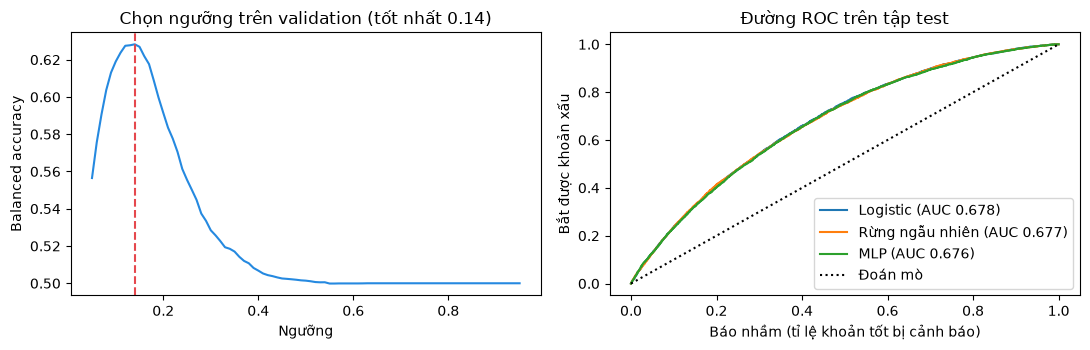

Ma trận nhầm lẫn của MLP (hàng = thật, cột = dự đoán):


,đoán: trả đủ,đoán: không trả đủ
thật: trả đủ,24013,11659
thật: không trả đủ,2746,3663


In [8]:
# Cell ML-08
def pick_threshold(y_val, p_val):
    grid = np.linspace(.05, .95, 91)
    scores = [balanced_accuracy_score(y_val, p_val >= t) for t in grid]
    return float(grid[int(np.argmax(scores))]), grid, scores

def evaluate(name, p_val, p_test):
    t, _, _ = pick_threshold(yv, p_val)
    pred = p_test >= t
    return {'Mô hình': name, 'Ngưỡng': round(t, 2), 'ROC-AUC': round(roc_auc_score(yt, p_test), 4),
            'Balanced acc.': round(balanced_accuracy_score(yt, pred), 4),
            'Bắt được khoản xấu (recall)': round(recall_score(yt, pred), 4),
            'Cảnh báo đúng (precision)': round(precision_score(yt, pred), 4)}

table = [evaluate(n, r['val'], r['test']) for n, r in runs.items()]
table.append(evaluate('MLP (NumPy)', mlp['scratch']['val'], mlp['scratch']['test']))
table.append({'Mô hình': 'Luôn đoán "trả đủ" (đối chứng)', 'Ngưỡng': 0.5, 'ROC-AUC': 0.5,
              'Balanced acc.': 0.5, 'Bắt được khoản xấu (recall)': 0.0, 'Cảnh báo đúng (precision)': float('nan')})
display(pd.DataFrame(table))
t, grid, scores = pick_threshold(yv, mlp['scratch']['val'])
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].plot(grid, scores, color='#2589e0'); axes[0].axvline(t, color='#e5484d', ls='--')
axes[0].set_title(f'Chọn ngưỡng trên validation (tốt nhất {t:.2f})'); axes[0].set_xlabel('Ngưỡng'); axes[0].set_ylabel('Balanced accuracy')
for name, p in [('Logistic', runs['Hồi quy logistic']['test']), ('Rừng ngẫu nhiên', runs['Rừng ngẫu nhiên']['test']),
                ('MLP', mlp['scratch']['test'])]:
    fpr, tpr, _ = roc_curve(yt, p)
    axes[1].plot(fpr, tpr, label=f'{name} (AUC {roc_auc_score(yt, p):.3f})')
axes[1].plot([0, 1], [0, 1], 'k:', label='Đoán mò'); axes[1].legend(); axes[1].set_xlabel('Báo nhầm (tỉ lệ khoản tốt bị cảnh báo)')
axes[1].set_ylabel('Bắt được khoản xấu'); axes[1].set_title('Đường ROC trên tập test')
plt.tight_layout(); plt.show()
print('Ma trận nhầm lẫn của MLP (hàng = thật, cột = dự đoán):')
display(pd.DataFrame(confusion_matrix(yt, mlp['scratch']['test'] >= t), index=['thật: trả đủ', 'thật: không trả đủ'],
                     columns=['đoán: trả đủ', 'đoán: không trả đủ']))

**Đọc kết quả.** ROC-AUC của cả ba mô hình đều xấp xỉ 0,68: **hơn đoán mò rõ rệt nhưng không cao**. Đường ROC xa đường chéo nhưng
còn xa góc trên trái. Với ngưỡng chọn trên validation, mô hình bắt được khoảng 57–69 trong 100 khoản xấu (tùy mô hình và hạt giống) nhưng chỉ khoảng 23–24%
cảnh báo là đúng (hơn ba phần tư số hồ sơ bị cảnh báo thật ra là hồ sơ tốt bị báo nhầm). Ba mô hình chênh nhau rất ít, nghĩa là **mạng nơ-ron không tự động tốt hơn
mô hình đơn giản** trên dữ liệu bảng cỡ này.

## 8. Giải thích một hồ sơ: vì sao mô hình đưa ra con số này?

Hàm `explain` lấy một hồ sơ thật ở tập test, rồi lần lượt **thay từng yếu tố bằng mức thông thường** (trung vị train; với nhóm: giá trị phổ biến)
và đo xác suất của MLP thay đổi bao nhiêu. Yếu tố làm xác suất đổi nhiều nhất là yếu tố ảnh hưởng nhất với hồ sơ này.
Đây chính là cách demo web trình bày "ba yếu tố ảnh hưởng nhất".

In [9]:
# Cell ML-09
test_csv = pd.read_csv(ROOT / 'data/tieuluan/app/loan_test.csv')
params = {k: data[k] for k in ('imputer_median', 'scaler_mean', 'scaler_scale', 'feature_names')}
mlp_model = build_models('mlp', x.shape[1:], seed=11, frameworks=('scratch',))['scratch'].load(
    ROOT / 'models/tieuluan/full/loan_default__mlp__scratch__11.npz')

def risk(values):
    """Xác suất không trả đủ của MLP (hạt giống 11) cho một hồ sơ dạng dict."""
    z = loan.preprocess(loan.build_features(pd.DataFrame([values])).to_numpy(), params)
    return float(sigmoid(predict_logits(mlp_model, 'scratch', z))[0])

TYPICAL = {'home_ownership': 'MORTGAGE', 'verification_status': 'Source Verified', 'purpose': 'debt_consolidation'}
medians = dict(zip(params['feature_names'], params['imputer_median']))

def explain(values):
    base = risk(values)
    rows = []
    for key in loan.INPUT_COLUMNS:
        alt = dict(values); alt[key] = TYPICAL.get(key, medians.get(key))
        rows.append({'Yếu tố': loan.FACTOR_NAME[key], 'Giá trị hồ sơ': values[key], 'Mức thông thường': alt[key],
                     'Xác suất đổi (điểm %)': round(100 * (base - risk(alt)), 2)})
    return base, pd.DataFrame(rows).sort_values('Xác suất đổi (điểm %)', key=abs, ascending=False)

row = test_csv.iloc[7]
values = {k: (loan.FIELD[k][5] if k in loan.FIELD and pd.isna(row[k]) else row[k]) for k in loan.INPUT_COLUMNS}
p, table = explain(values)
print(f'Hồ sơ thật số 8 của tập test: MLP ước lượng {p:.1%} khả năng không trả đủ; kết cục thật = {int(row["default"])} (1 = không trả đủ).')
display(table.head(5).reset_index(drop=True))

Hồ sơ thật số 8 của tập test: MLP ước lượng 23.2% khả năng không trả đủ; kết cục thật = 1 (1 = không trả đủ).


,Yếu tố,Giá trị hồ sơ,Mức thông thường,Xác suất đổi (điểm %)
0,Số năm đi làm,2.0,6.0,-5.54
1,Số tài khoản tín dụng đang mở,24.0,10.0,5.34
2,Thu nhập hằng năm,46000.0,60000.0,5.06
3,Số tiền xin vay,16000.0,10000.0,4.78
4,Tỷ lệ nợ trên thu nhập (DTI),21.63,16.54,2.38


## 9. Ba hạt giống và khoảng tin cậy (đọc từ kết quả đã lưu)

Một lần huấn luyện có thể may rủi, nên mỗi mô hình được huấn luyện với 3 hạt giống (11, 22, 33). Bảng cho trung bình ± độ lệch chuẩn
của ROC-AUC. Khoảng tin cậy 95% bootstrap (lấy mẫu lại tập test 2.000 lần) cho biết độ bất định do chỉ có 42.081 khoản test.

In [10]:
# Cell ML-10
frame = pd.DataFrame([{'Mô hình': r['kind'], 'Cài đặt': r['framework'], 'roc_auc': r['metrics']['roc_auc'],
                       'balanced_accuracy': r['metrics']['balanced_accuracy'], 'recall': r['metrics']['recall']}
                      for r in records if r['framework'] != 'baseline'])
display(frame.groupby(['Mô hình', 'Cài đặt']).agg(auc_tb=('roc_auc', 'mean'), auc_dlc=('roc_auc', 'std'),
        bacc=('balanced_accuracy', 'mean'), recall=('recall', 'mean'), so_lan=('roc_auc', 'size')).round(4))
analysis = json.loads((RESULTS / 'analysis.json').read_text(encoding='utf-8'))['uci']['loan_default']
display(pd.DataFrame([{'So sánh': k, 'Giá trị': round(v.get('auc', v.get('difference')), 4), 'CI95 thấp': round(v['low'], 4),
                       'CI95 cao': round(v['high'], 4)} for k, v in analysis.items()]))

auc_tb  auc_dlc    bacc  recall  so_lan
Mô hình       Cài đặt                                         
logistic      sklearn  0.6780   0.0000  0.6282  0.6388       3
mlp           keras    0.6766   0.0022  0.6278  0.6859       3
              pytorch  0.6766   0.0023  0.6279  0.6855       3
              scratch  0.6767   0.0023  0.6263  0.6527       3
random_forest sklearn  0.6768   0.0004  0.6252  0.5908       3

,So sánh,Giá trị,CI95 thấp,CI95 cao
0,logistic,0.6780,0.6713,0.6847
1,random_forest,0.6772,0.6702,0.6838
2,mlp,0.6815,0.6746,0.6882
3,rf_minus_mlp,-0.0043,-0.0073,-0.0014
4,mlp_minus_logistic,0.0035,0.0014,0.0056


## 10. Câu hỏi để trình bày

1. Vì sao chia train/val/test **theo thời gian** thay vì ngẫu nhiên? Nếu chia ngẫu nhiên kết quả sẽ đẹp hơn hay xấu đi, và vì sao đó là ảo tưởng?
2. Tại sao accuracy 86% không chứng tỏ mô hình tốt khi 86% khoản vay đều trả đủ? Thước đo nào thay thế?
3. Chuẩn hóa và điền khuyết chỉ học trên train để tránh rò rỉ nào?
4. Cột nào trong dữ liệu gốc **cố ý không dùng** (ví dụ `total_pymnt`, `last_pymnt_d`) và vì sao?
5. Ba mô hình chênh nhau rất ít: kết luận gì về lựa chọn MLP so với hồi quy logistic cho dữ liệu bảng?
6. Lãi suất do chính nền tảng ấn định đã chứa đánh giá rủi ro của họ: điều đó ảnh hưởng thế nào tới việc giải thích "yếu tố quan trọng"?
7. Nếu dùng mô hình này để từ chối cho vay ngoài đời, có rủi ro công bằng nào (tuổi, nơi ở, nhóm thu nhập)? Dữ liệu 2012–2015 ở Mỹ có áp dụng được cho Việt Nam không?